In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#Random seed
rng = np.random.default_rng(42)

#Global parameters: number of steps, number of instances of the random walk
steps = 1000
N = 100

In [3]:
#Task 1 - Lattice motion
def lattice_motion(l_steps, l_N, dim, rng):
    #Possible directions of movement in 2D lattice
    if dim == 2:
        direction = np.array([[1,0],[-1,0],[0,1],[0,-1]], dtype = np.int8)
    #Possible directions of movement in 3D lattice
    elif dim == 3:
        direction = np.array([[1,0,0],[-1,0,0],[0,1,0],[0,-1,0],[0,0,1],[0,0,-1]], dtype = np.int8)
    else:
        raise ValueError("Dimension must be an integer of value 2 or 3.")
    index = rng.integers(len(direction), size = (l_N,l_steps), dtype = np.int8)
    displacement = direction [index]
    positions = np.cumsum(displacement, axis = 1, dtype = np.int32)
    origin = np.zeros((l_N, 1, dim), dtype = positions.dtype)
    positions = np.concatenate([origin, positions], axis = 1)
    return positions

In [4]:
#Test run for lattice_motion
stps = 1000
n = 100
dim = 2
test = lattice_motion(stps, n, dim, rng)
print (test.shape)
print (test[:,0])
print (np.abs(np.diff(test, axis=1)).sum(axis = -1))

(100, 1001, 2)
[[0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]]
[[1 1 1 ... 1 1 1]
 [1 1 1 ... 1 1 1]
 [1 1 1 ... 1 1 1]
 ...
 [1 1 1 ... 1 1 1]
 [1 1 1 ... 1 1 1]
 [1 1 1 ... 1 1 1]]


In [5]:
# Task 2 - Investigation of expected distance from the origin after n steps for lattice motion
def theor_exp_dist (l_steps, dim):
    n = np.arange(l_steps+1)
    if dim == 2:
        E_Rn = np.sqrt ((np.pi*n)/4)
    elif dim == 3:
        E_Rn = np.sqrt ((8*n)/(3*np.pi))
    else: 
        raise ValueError ("Dimension must be an integer of value 2 or 3.")
    return E_Rn

def emp_exp_dist (l_steps, l_N, dim, rng):
    temp = lattice_motion(l_steps, l_N, dim, rng)
    d = np.linalg.norm(temp.astype(float),axis = 2)
    E_Rn = np.mean (d, axis = 0)
    std_err = np.std (d, axis = 0, ddof = 1)/np.sqrt(temp.shape[0])
    return E_Rn, std_err

In [6]:
#Test run of theor_exp_dist and emp_exp_dist
t = theor_exp_dist (stps, dim)
e, s = emp_exp_dist (stps, n, dim, rng)
print (t[1], e[1], s[1])

0.8862269254527579 1.0 0.0


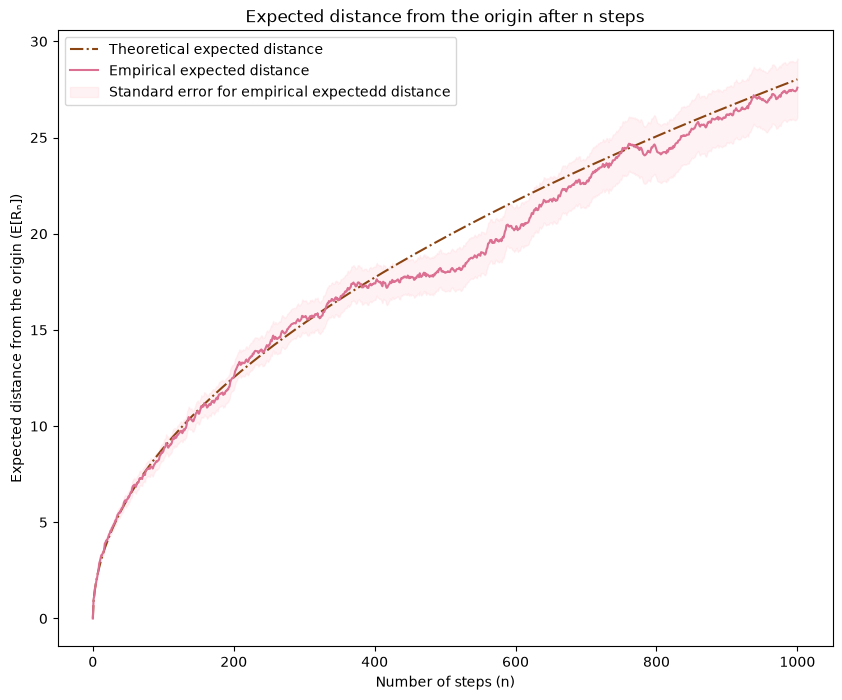

In [ ]:
#Plotting the expected distance from the origin after n steps for lattice motion
x = np.arange(0, stps+1)
plt.figure(figsize=(10,8), dpi = 100)
plt.plot(x,t, label = 'Theoretical expected distance', color = 'saddlebrown', linestyle = '-.')
plt.plot (x,e, label = 'Empirical expected distance', color = 'palevioletred', linestyle ='-')
plt.fill_between(x, e-s, e+s, color = 'pink', alpha = 0.2, label = 'Standard error for empirical expectedd distance')
plt.title('Expected distance from the origin after n steps')
plt.xlabel ('Number of steps (n)')
plt.ylabel ('Expected distance from the origin (E[R\u2099])')
plt.legend()
plt.show()